# 7층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 배터리 수명 직선으로 맞히고 남은 무늬 보기

**프롬프트**

> battery_sim.csv(시뮬레이션 600개)로 배터리 수명(cycles)을 선형 회귀로 맞혀 주세요.
> 시험용 R²를 출력하고, 가로축 평균 온도·세로축 잔차(실제−예측) 그래프를 그려
> 남은 무늬가 있는지 보여 주세요(그래프 글자는 영어).

시험용 R²: 0.916
계수: {'avg_temp': -27.7, 'fast_charge': -468.5, 'depth_of_discharge': -535.2, 'daily_use': -67.4}


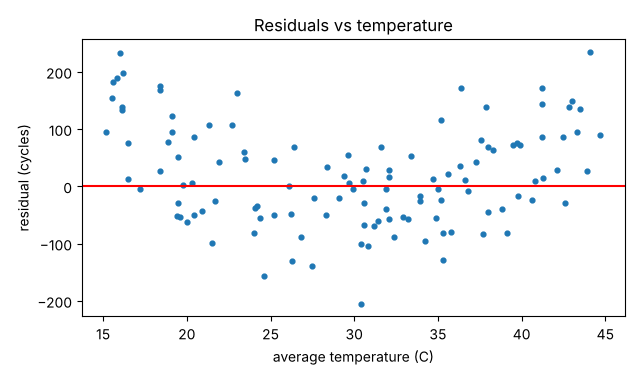

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/battery_sim.csv")
X = df[["avg_temp", "fast_charge", "depth_of_discharge", "daily_use"]]
y = df["cycles"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lin = LinearRegression().fit(X_train, y_train)
print("시험용 R²:", round(lin.score(X_test, y_test), 3))
print("계수:", {c: round(float(w), 1) for c, w in zip(X.columns, lin.coef_)})

resid = y_test - lin.predict(X_test)
plt.scatter(X_test["avg_temp"], resid, s=12)
plt.axhline(0, color="red")
plt.xlabel("average temperature (C)"); plt.ylabel("residual (cycles)"); plt.title("Residuals vs temperature")
plt.show()

**박사의 한 줄 판단** — R² 0.916으로 잘 맞는 것 같지만, 잔차가 낮은 온도와 높은 온도 양쪽에서 위로 휘는 U자 무늬를 남겼습니다. 직선이 놓친 곡선 관계가 있다는 신호입니다.

## 실습 2 · 곡선·숲·부스팅 — 학습 점수와 시험 점수의 차이

**프롬프트**

> battery_sim.csv로 다항(2차)+Ridge, 랜덤포레스트(300그루), 그래디언트 부스팅을 비교해 주세요.
> 학습 R²와 시험 R², 그 차이(격차)를 표로 보여 주세요.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

df = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/battery_sim.csv")
X = df[["avg_temp", "fast_charge", "depth_of_discharge", "daily_use"]]
y = df["cycles"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {"다항+Ridge": make_pipeline(PolynomialFeatures(2), StandardScaler(), Ridge(alpha=1.0)),
          "랜덤포레스트": RandomForestRegressor(n_estimators=300, random_state=0),
          "부스팅": GradientBoostingRegressor(random_state=0)}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    tr, te = m.score(X_train, y_train), m.score(X_test, y_test)
    rows.append([name, round(tr, 3), round(te, 3), round(tr - te, 3)])
print(pd.DataFrame(rows, columns=["모델", "학습 R²", "시험 R²", "격차"]).to_string(index=False))

      모델  학습 R²  시험 R²    격차
다항+Ridge  0.949  0.945 0.004
  랜덤포레스트  0.989  0.931 0.059
     부스팅  0.978  0.934 0.045


**박사의 한 줄 판단** — 다항+Ridge가 시험 R² 0.945로 가장 높고 격차도 0.004로 가장 작습니다. 숲은 학습 0.989로 높지만 격차 0.059 — 조금 외웠어요. 이 데이터는 곡선 관계를 넣어 만든 시뮬레이션이라 곡선 모델이 유리하다는 점도 기억하세요.